# Figure 4: Reward Rate vs. Bound

Translation of `Figure04_RRvsBound.m`; bounds from the trial-level stopping model (2026-10-10).

## What this notebook does

Shows how participants' decision bounds relate to their reward rate across three blocks in the online (OL) task, and how bounds adapt during the first 40 trials of each block.

**Bounds come from the stopping model** (`pigeon.stopping`, notebook `Test_stoppingModel`):
each subject's trials are fit with a bound that collapses from step 1 to a knee (typically
step 2–4) and then declines gently, plus sensory noise, guesses, lapses and anticipations.
The **bound at the knee** (`bound_scale`) is the single bound measure. Fits are made by
`scripts/run_stopping_fits.py` and cached in `data/processed/stopping_fits_main.pkl`.

**Formatted figure (2 rows × 3 columns)**:
- **Top row** (one panel per block): Scatter of the fitted bound at the knee (x) vs. reward rate (y) per subject, with a simulation ribbon (5th–95th percentile from 100 simulated subjects with a fixed bound, the optimal policy). Dashed crosshair lines mark the optimal bound (blue, peak of ideal RR curve) and the participant median (black).
- **Bottom row** (one panel per block): Within-block adaptation curve of the z-scored bound residual (measured bound minus the model's expected measured bound at that DT; mean ± SEM ribbon) with permutation null band, plus a small τ inset.

**Bound comparison across blocks** (standalone, not in final figure): scatter of the fitted bound in block 1 vs. block 2 and block 2 vs. block 3.

**Data**: OL task, blocks 1–3, lowest SNR condition (raw blocks 1–3).

## Imports

Imports standard scientific Python libraries and pigeon analysis functions. No data loading or filtering.

## Load data

Loads all OL (online) trials via `get_data_table(task_type='OL')`. This reads all subject CSV files, computes bounds and DTs, marks wall hits, and applies bias correction if available.

## Compute bound and coin summaries

**Fitted bound at the knee** (`stopping_fits_main.pkl`, OL raw blocks 1–3 = the low-SNR
condition of combined blocks 1–3): one value per subject × block. Fits use the stopping
model's trial selection (`get_stopping_model_trials`: trial_number ≥ max(10, ceil τ), no
DT cutoff, no wall-hit exclusion, raw positions). Error bars in panels A–C are the
fitted trial-to-trial SD of the bound at the knee (`bound_scale × bound_cv`).

**Coin summary** (computed inline):
- For each (subject, block, SNR), takes the last `coin_count` value (cumulative total at end of block)
- Reward rate = total coins / 600 steps per block
- **Data included**: All trials sorted by trial number; last coin_count value per group
- **Data excluded**: Subjects/blocks/SNRs with no valid trials

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import pandas as pd
from pathlib import Path

from pigeon.data import get_data_table
from pigeon.simulation import get_simulated_data_table, BLOCK_DEFAULTS
from pigeon.stopping import get_bound_residuals
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label, CONDITION_LABELS

In [2]:
data_table_ol = get_data_table(task_type='OL')

In [3]:
BLOCKS    = [1, 2, 3]
SNR_INDEX = 0  # first (lowest) SNR level

subjects   = np.sort(data_table_ol['subject_index'].dropna().unique())
n_subjects = len(subjects)

# Fitted bound at the knee per subject x block (raw blocks 1-3 = low SNR), and the fitted
# trial-to-trial SD of the bound there (bound_scale * bound_cv) for the error bars.
PROCESSED = Path('../data/processed')
stopping_fits_ol = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl').query("task == 'OL'")
_fit = stopping_fits_ol[stopping_fits_ol['group'].isin([f'B{b}' for b in BLOCKS])]
knee_bound = (_fit.pivot(index='subject_index', columns='group', values='bound_scale')
              .reindex(index=subjects, columns=[f'B{b}' for b in BLOCKS]).to_numpy())
knee_bound_sd = knee_bound * (_fit.pivot(index='subject_index', columns='group', values='bound_cv')
                              .reindex(index=subjects, columns=[f'B{b}' for b in BLOCKS]).to_numpy())
print('knee_bound shape:', knee_bound.shape, '| subjects without a fit, by block:',
      np.isnan(knee_bound).sum(axis=0))

# Compute coin_summary: total coins per subject × block × SNR
# coin_count is a cumulative running total, so we take the last value (sorted by trial_number)
# Dividing by 600 (steps_per_block) gives reward rate
abs_snr  = np.abs(data_table_ol['snr'].to_numpy())
snr_vals = np.sort(np.unique(abs_snr[np.isfinite(abs_snr)]))
n_snrs   = len(snr_vals)

# Simulation constants for the RR ribbon in the formatted figure
GENERATIVE_STD  = 0.15                                         # per-step noise SD (matches real OL task)
GENERATIVE_MEAN = float(snr_vals[SNR_INDEX]) * GENERATIVE_STD  # drift for SNR_INDEX
SIM_BOUNDS      = np.arange(0.01, 0.82, 0.02)                 # bound sweep for RR ribbon (to the panel edge)
NUM_SIM_SUBJ    = 100                                          # simulated subjects per bound value
print(f'SNR levels: {np.round(snr_vals, 3)},  GENERATIVE_MEAN={GENERATIVE_MEAN:.4f} '
      f'(SNR={GENERATIVE_MEAN/GENERATIVE_STD:.3f})')

# Sort once up front so the inner loop just slices, no per-iteration sort
_dt_sorted      = data_table_ol.sort_values('trial_number')
_abs_snr_sorted = np.abs(_dt_sorted['snr'].to_numpy())

coin_summary = np.full((n_subjects, len(BLOCKS), n_snrs), np.nan)

for si, subj in enumerate(subjects):
    for bi, block in enumerate(BLOCKS):
        for ni, snr_val in enumerate(snr_vals):
            ls = (
                (_dt_sorted['subject_index'] == subj) &
                (_dt_sorted['block_index']   == block) &
                np.isclose(_abs_snr_sorted, snr_val)
            )
            if ls.any():
                vals = _dt_sorted.loc[ls, 'coin_count'].dropna()
                if len(vals) > 0:
                    coin_summary[si, bi, ni] = vals.iloc[-1]

print('coin_summary shape:', coin_summary.shape)

knee_bound shape: (60, 3) | subjects without a fit, by block: [0 0 1]
SNR levels: [0.333 1.   ],  GENERATIVE_MEAN=0.0500 (SNR=0.333)


coin_summary shape: (60, 3, 2)


## Bound summary statistics per block

For each block, reports the median [IQR] across participants of the **fitted bound at the knee**.

In [4]:
for bi, block in enumerate(BLOCKS):
    vals = knee_bound[:, bi]
    vals = vals[np.isfinite(vals)]
    q25, med, q75 = np.percentile(vals, [25, 50, 75])
    print(f'block {block}: {med:.3f} [{q25:.3f}, {q75:.3f}]')

block 1: 0.235 [0.111, 0.341]
block 2: 0.459 [0.297, 0.604]
block 3: 0.308 [0.208, 0.444]


## Spearman correlation: fitted bound vs. reward rate, per block

For each block, reports the Spearman ρ and associated p-value between each participant's fitted bound at the knee and their reward rate (total coins / 600 steps). Only subjects with finite values for both measures are included.

In [5]:
for bi, block in enumerate(BLOCKS):
    mean_bound  = knee_bound[:, bi]
    reward_rate = coin_summary[:, bi, SNR_INDEX] / BLOCK_DEFAULTS[1]['steps_per_block']
    valid = np.isfinite(mean_bound) & np.isfinite(reward_rate)
    r, p = scipy.stats.spearmanr(mean_bound[valid], reward_rate[valid])
    print(f'Block {block}: Spearman r={r:.3f}, p={p:.3f}')

Block 1: Spearman r=-0.487, p=0.000
Block 2: Spearman r=0.421, p=0.001
Block 3: Spearman r=0.079, p=0.550


## Bound comparison across blocks

Scatter of the fitted bound at the knee, block 1 vs. block 2 (left) and block 2 vs. block 3 (right). One point per subject. Not part of the final figure.

Block 1 vs 2: median diff=0.17 [0.10 0.32], p=0.000, Spearman r=0.54 (p=0.000)
   RR: Spearman r=-0.46 (p=0.000)
Block 2 vs 3: median diff=-0.09 [-0.18 0.01], p=0.000, Spearman r=0.45 (p=0.000)
   RR: Spearman r=0.17 (p=0.203)


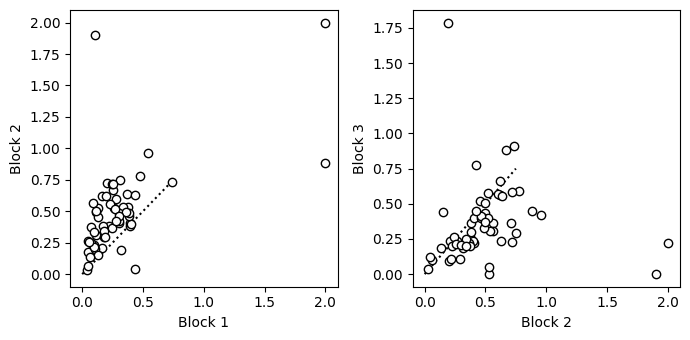

In [6]:
wt = (0.99, 0.99, 0.99)  # near-white marker fill

comparisons = [(0, 1, 1, 2), (1, 2, 2, 3)]  # (bi_x, bi_y, label_x, label_y)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))

for ax, (bx, by, lx, ly) in zip(axs, comparisons):
    xs = knee_bound[:, bx]  # fitted bound at the knee, block lx
    ys = knee_bound[:, by]  # fitted bound at the knee, block ly

    valid = np.isfinite(xs) & np.isfinite(ys)

    # Identity line
    ax.plot([0, 0.75], [0, 0.75], 'k:')

    # One point per subject
    ax.plot(xs[valid], ys[valid], 'ko', markerfacecolor=wt)

    ax.set_xlabel(f'Block {lx}')
    ax.set_ylabel(f'Block {ly}')

    # Stats: median diff with IQR, Wilcoxon signed-rank, Spearman correlation
    diff = ys[valid] - xs[valid]
    pcts = np.percentile(diff, [25, 50, 75])
    _, p_rank = scipy.stats.wilcoxon(xs[valid], ys[valid])
    r, p_corr = scipy.stats.spearmanr(xs[valid], ys[valid])
    print(f'Block {lx} vs {ly}: median diff={pcts[1]:.2f} [{pcts[0]:.2f} {pcts[2]:.2f}], '
          f'p={p_rank:.3f}, Spearman r={r:.2f} (p={p_corr:.3f})')

    # RR correlation
    xrs = coin_summary[:, bx, SNR_INDEX][valid] / BLOCK_DEFAULTS[1]['steps_per_block']
    yrs = coin_summary[:, by, SNR_INDEX][valid] / BLOCK_DEFAULTS[1]['steps_per_block']
    rr, pr = scipy.stats.spearmanr(xrs, yrs)
    print(f'   RR: Spearman r={rr:.2f} (p={pr:.3f})')

plt.tight_layout()
plt.show()

## Within-block bound adaptation: methods

**Note on block numbering.** The top-row panels (A–C) above use `data_table_ol`, loaded
with the default `combine_snr=True`, which merges the raw 6-block OL task into 3 blocks
(raw blocks 4-6 are folded into 1-3). The tau/adaptation panels below (D–F) instead use a
separately loaded `data_table_ol_blocks = get_data_table(task_type='OL', combine_snr=False)`,
keeping the raw, unmerged 6-block numbering, so "Block 1/2/3" in the bottom row refers only
to each block's first raw exposure. This is necessary because within-block adaptation is
fit from trial 1 onward, and a combined "block" is actually two separate 40-trial exposures
concatenated — fitting a single from-trial-1 curve across that boundary would not be
meaningful.

For each subject × block, the code below computes a smoothed z-scored **bound residual**
curve over the first 40 trials and tests whether it shows reliable time-locked
structure relative to a permutation null.  The resulting curves and τ fits are
shown as the bottom row of the formatted figure.

**Bound residual** (`pigeon.stopping.get_bound_residuals`). The measured |bound| of a
trial (from `get_bounds`, raw positions) depends on its DT through the bound's
within-trial collapse, overshoot and the congruence-based DT assignment, not only on
the subject's bound setting. Each subject × block is therefore simulated 20 times over
its trials from its stopping-model fit, the simulated trials are run through the same
`get_bounds` inference, and the mean measured |bound| at each DT (DT ≥ 10 pooled) is the
expected measured bound. The residual is measured − expected. The fits exclude each
block's adaptation transient, so the expectation is the steady state and early-trial
residuals measure the deviation from it. Trials are filtered as before (DT ≥ 2, no wall
hit, RT cutoff; no trial-number floor, since trial number is the x-axis).

**Smoothed z-scored curve.** The residual is z-scored per subject × block, then smoothed with a ±3-trial sliding window.  We also compute 1000
permutations of each subject's own trial order within the block — preserving that
subject's noise level but destroying any time structure — giving a null distribution
specific to each subject.  The max-stat (Tmax, 95th percentile over all 40 trials)
of the group-mean null curves provides a multiple-comparison-corrected threshold.

**τ-fit eligibility.** Block 1 is gated by a within-block permutation test on the
residual curve (no preceding block).  Blocks 2 and 3 are gated by a per-subject Mann-Whitney U
test on steady-state measured |bound| (residuals are ~0 at steady state in every block by
construction, so they cannot show a change between blocks) between block[i−1] and block[i] — a subject can shift
reliably between blocks without that shift resolving as a clean within-block
exponential settle, so these criteria are kept separate.  Fits that hit the `tau_max`
boundary are excluded from the τ summary (shown as open triangles in the figure)
since they represent a lower bound, not a measurement.

In [7]:
from pigeon.adaptation import (
    compute_per_subject_curves_with_nulls,
    per_subject_significance,
    group_null_band,
    between_block_significance,
    fit_exp_tau,
)
from pigeon.data import get_good_trial_array

SUPP_MAX_TRIAL = 40
SUPP_BLOCKS    = [1, 2, 3]
SUPP_HALF_WIN  = 3
SUPP_MIN_WIN   = 3
N_PERM         = 1000
PERM_SEED      = 123
SIG_ALPHA      = 0.05
BETWEEN_MIN_TRIALS = 5  # min good trials per block required to run the between-block test
RESID_REPS = 20         # simulated repetitions per trial for the expected measured bound
RESID_SEED = 20261010
ADAPT_COL  = 'bound_residual'   # per-trial quantity for the adaptation curves (z-scored)

In [8]:
# Load OL data retaining all 6 raw blocks (combine_snr=False) for per-block analysis
data_table_ol_blocks = get_data_table(task_type='OL', combine_snr=False)

# Bound residuals (measured |bound| - model-expected measured |bound| at that DT), from the
# raw (not bias-corrected) bounds; same trials and order as data_table_ol_blocks.
_raw = get_data_table(task_type='OL', combine_snr=False, correct_bias=None)
assert (_raw.index == data_table_ol_blocks.index).all()
_raw = _raw[_raw['block_index'].isin(SUPP_BLOCKS) & _raw['choice'].notna()].copy()
_raw['condition'] = [f'B{b:.0f}' for b in _raw['block_index']]
data_table_ol_blocks = data_table_ol_blocks.join(
    get_bound_residuals(_raw, stopping_fits_ol, num_reps=RESID_REPS, rng=np.random.default_rng(RESID_SEED)))
_lg = get_good_trial_array(data_table_ol_blocks, min_trial_number=None, block_index=SUPP_BLOCKS)
print(f'residuals for {data_table_ol_blocks.loc[_lg, ADAPT_COL].notna().sum()} of {_lg.sum()} filtered trials '
      '(the rest: too few simulated trials at their DT)')

supp_trial_nums, supp_real, supp_perm, supp_subjects = compute_per_subject_curves_with_nulls(
    data_table_ol_blocks, SUPP_MAX_TRIAL, SUPP_BLOCKS,
    half_win=SUPP_HALF_WIN, min_win=SUPP_MIN_WIN, n_perm=N_PERM, seed=PERM_SEED,
    value_col=ADAPT_COL, zscore=True)

# Group mean ± SEM for ribbon plots (all subjects, for display)
_n_valid       = np.sum(np.isfinite(supp_real), axis=0)
supp_mean      = np.nanmean(supp_real, axis=0)
supp_sem       = np.nanstd(supp_real, axis=0) / np.sqrt(np.maximum(_n_valid, 1))
supp_sem[_n_valid < 2] = np.nan

# Permutation-based group null band (max-stat corrected across the 40 trials) -- this
# and the within-block significance test below still describe the *within-block* curve
# shown in the top row, independent of which criterion gates the tau fits below.
supp_null_thresh = group_null_band(supp_perm, alpha=SIG_ALPHA)
supp_pvals, supp_sig = per_subject_significance(supp_real, supp_perm, alpha=SIG_ALPHA)

# Between-block significance: for blocks 2 and 3, does this subject's steady-state
# |bound| reliably differ from the immediately preceding block? (block 1 has no
# preceding block, so this is undefined there -- column 0 is all False/NaN.)
supp_between_pvals, supp_sig_between = between_block_significance(
    data_table_ol_blocks, SUPP_BLOCKS, alpha=SIG_ALPHA, min_trials=BETWEEN_MIN_TRIALS)

# Tau-fit eligibility: block 1 uses the within-block adaptation test (no alternative
# exists); blocks 2 and 3 use the between-block change test instead. supp_sig_between
# is computed independently with its own, looser trial-count filter, so it can flag a
# subject as eligible even if they have no finite curve point anywhere in the block
# (e.g. too few trials for compute_per_subject_curves_with_nulls' local window
# requirement) -- gate blocks 2/3 with has_curve so eligibility never outstrips the
# subjects that actually have a curve to fit (block 1 is already implicitly gated:
# per_subject_significance leaves pvals/sig as NaN/False wherever a subject has no
# curve data).
has_curve = np.any(np.isfinite(supp_real), axis=1)  # (n_subjects, n_blocks)
supp_sig_tau = supp_sig.copy()
supp_sig_tau[:, 1:] = supp_sig_between[:, 1:] & has_curve[:, 1:]

# Per-subject exponential fits -- only for subjects classified as eligible above.
# `censored` flags fits that hit tau_max: a real (eligible) deviation that isn't well
# described by a fast exponential settle within the 40-trial window (e.g. slow drift) --
# these are excluded from the tau summary/plot rather than silently padding it at the cap.
supp_taus     = np.full((len(supp_subjects), len(SUPP_BLOCKS)), np.nan)
supp_censored = np.zeros((len(supp_subjects), len(SUPP_BLOCKS)), dtype=bool)
for bi in range(len(SUPP_BLOCKS)):
    for si in range(len(supp_subjects)):
        if supp_sig_tau[si, bi]:
            tau, censored = fit_exp_tau(supp_trial_nums, supp_real[si, :, bi], tau_max=SUPP_MAX_TRIAL)
            supp_taus[si, bi]     = tau
            supp_censored[si, bi] = censored

print('Per-block adaptation summary:')
for bi, block in enumerate(SUPP_BLOCKS):
    n_total   = np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1))
    n_within  = np.sum(supp_sig[:, bi])
    mean_curve = supp_mean[:, bi]
    max_abs   = np.nanmax(np.abs(mean_curve))
    exceeds   = max_abs > supp_null_thresh[bi]
    print(f'  Block {block}: {n_within}/{n_total} subjects show within-block adaptation '
          f'({100 * n_within / max(n_total, 1):.0f}%)')
    print(f'    group mean curve: max|curve|={max_abs:.3f} vs. null threshold '
          f'±{supp_null_thresh[bi]:.3f} -> {"exceeds null" if exceeds else "within null"}')

    # n_qual = np.sum(supp_sig_tau[:, bi]), i.e. the actual eligibility mask used
    # for tau fitting below -- guaranteed <= n_total since supp_sig_tau is gated by
    # has_curve (see above).
    n_qual = np.sum(supp_sig_tau[:, bi])
    crit_label = ('within-block adaptation (no preceding block)' if bi == 0
                  else f'significant change vs. block {SUPP_BLOCKS[bi - 1]} (Mann-Whitney U)')
    print(f'    tau-fit eligibility: {n_qual}/{n_total} subjects qualify ({crit_label})')

    is_censored = supp_censored[:, bi]
    vt = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_censored]
    n_cens = np.sum(is_censored)
    if len(vt):
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'    τ (eligible, non-censored): median={med:.1f}  '
              f'IQR=[{q25:.1f}, {q75:.1f}]  n={len(vt)}  '
              f'(+{n_cens} censored at tau_max, excluded)')
    else:
        print(f'    τ: no uncensored fits ({n_cens} eligible subjects censored at tau_max)')

residuals for 8778 of 9014 filtered trials (the rest: too few simulated trials at their DT)


Per-block adaptation summary:
  Block 1: 6/55 subjects show within-block adaptation (11%)
    group mean curve: max|curve|=0.198 vs. null threshold ±0.197 -> exceeds null
    tau-fit eligibility: 6/55 subjects qualify (within-block adaptation (no preceding block))
    τ (eligible, non-censored): median=1.7  IQR=[1.7, 1.7]  n=1  (+5 censored at tau_max, excluded)
  Block 2: 8/56 subjects show within-block adaptation (14%)
    group mean curve: max|curve|=0.347 vs. null threshold ±0.195 -> exceeds null
    tau-fit eligibility: 40/56 subjects qualify (significant change vs. block 1 (Mann-Whitney U))
    τ (eligible, non-censored): median=6.6  IQR=[3.4, 15.1]  n=24  (+15 censored at tau_max, excluded)
  Block 3: 7/54 subjects show within-block adaptation (13%)
    group mean curve: max|curve|=0.166 vs. null threshold ±0.203 -> within null
    tau-fit eligibility: 16/54 subjects qualify (significant change vs. block 2 (Mann-Whitney U))
    τ (eligible, non-censored): median=4.3  IQR=[3.5, 6

## Formatted figure

Two-row × three-column figure saved to `Figure04.pdf`.

**Top row** (one panel per block): Scatter of the fitted bound at the knee (x; error bars
= fitted trial-to-trial SD) vs. reward rate (y) per subject.  Light blue ribbon = 5th–95th percentile of simulated reward rate vs. bound
(100 subjects).  Two sets of dashed crosshair lines project to both axes, using the
same color convention as Figure02c (blue = ideal/simulated benchmark, black =
empirical participant data):
- **Blue** — the simulated median RR curve itself, and its peak (optimal bound).
- **Black** — median bound and median reward rate across participants.

**Bottom row** (one panel per block): Group-mean ± SEM ribbon of the smoothed
z-scored bound-residual curve over the first 40 trials, in black (empirical data). Light
gray band = permutation null (max-stat corrected, 95%).  Lower-right inset:
box/jitter plot of τ (exponential time constant) for subjects with a successful,
non-censored fit; censored fits (τ pinned at tau_max = 40) are omitted from the
plot entirely rather than shown as a separate marker. The label above each inset
reads `n = <fit>/<total>`: the number of subjects with a plotted τ over the total
number of subjects with usable data in that block.

Block 1: 2 subject(s) with fitted bound > 0.8 drawn at the edge: bounds [2. 2.], reward rates [0.23 0.18] (0 below the axis break)
Block 2: 4 subject(s) with fitted bound > 0.8 drawn at the edge: bounds [0.96 1.9  2.   0.88], reward rates [ 0.01 -0.72 -0.73 -0.38] (3 below the axis break)
Block 3: 3 subject(s) with fitted bound > 0.8 drawn at the edge: bounds [0.88 1.79 0.91], reward rates [0.05 0.05 0.03] (0 below the axis break)


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


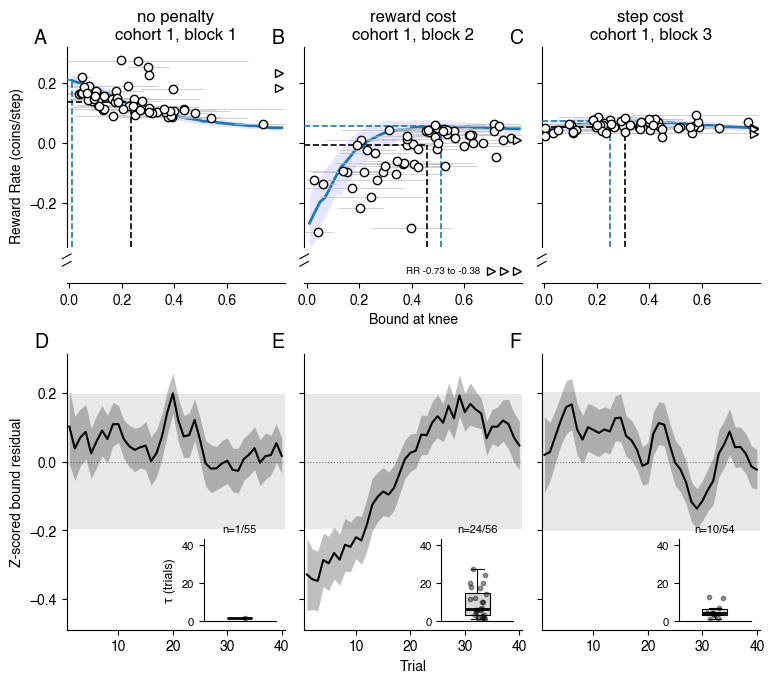

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure04.pdf (+ .png)

τ fits (eligible, non-censored):
  Block 1: insufficient fits  (n=1 good, 5 censored, 6 eligible)
  Block 2: median=6.6 [3.4, 15.1]  (n=24 good fits, 15 censored, 41 eligible)
  Block 3: median=4.3 [3.5, 6.5]  (n=10 good fits, 6 censored, 17 eligible)


In [9]:
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 17.6
HTS = [6.0, 7.0]
PSH = 1.8
PSW = 0.5
FS  = 12

fig_h       = sum(HTS) + PSH
panel_w     = (WID - 2 * PSW) / 3
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig_comb = plt.figure(figsize=(WID * CM, fig_h * CM))
gs_comb  = gridspec.GridSpec(2, 3, figure=fig_comb,
                              height_ratios=HTS,
                              hspace=hspace_frac, wspace=wspace_frac,
                              left=0, right=1, bottom=0, top=1)
axs_top = [fig_comb.add_subplot(gs_comb[0, c]) for c in range(3)]
axs_bot = [fig_comb.add_subplot(gs_comb[1, c]) for c in range(3)]

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

gr_c = (0.75, 0.75, 0.75)
wt_c = (0.99, 0.99, 0.99)
rp_c = (0.9,  0.9,  1.0)

# Color convention (consistent with Figure02c): blue = ideal/simulated benchmark,
# black = empirical participant data.
OPT_COLOR  = 'tab:blue'   # simulated RR curve and the peak of that curve
DATA_COLOR = 'k'          # median of the empirical data

# ── Pre-compute simulation ribbons for all blocks (single RNG pass) ───────────
# Done up-front so we can determine axis limits before drawing anything.
rng_comb = np.random.default_rng(0)
sbd_all = []
for bi, block in enumerate(BLOCKS):
    sbd = np.full((len(SIM_BOUNDS), 3), np.nan)
    for ss, bnd in enumerate(SIM_BOUNDS):
        sim_table = get_simulated_data_table(
            specs={'num_subjects': NUM_SIM_SUBJ, 'blocks': block},
            generative_mean=GENERATIVE_MEAN,
            bound_mean=bnd,
            rng=rng_comb,
        )
        sim_coins = sim_table.groupby('subject_index')['coin_count'].last().to_numpy()
        sbd[ss] = np.percentile(sim_coins, [5, 50, 95]) / BLOCK_DEFAULTS[1]['steps_per_block']
    sbd_all.append(sbd)

# Axis limits that keep every optimal-RR crosshair in frame
all_opt_idx = [int(np.nanargmax(sbd[:, 1])) for sbd in sbd_all]
all_opt_x   = [float(SIM_BOUNDS[i]) for i in all_opt_idx]
all_opt_y   = [float(sbd_all[bi][all_opt_idx[bi], 1]) for bi in range(3)]
x_left      = min(0.0, min(all_opt_x) - 0.02)   # extend left if any optimal is at/near x=0
y_top       = max(max(all_opt_y) * 1.08, 0.32)
# Fitted bounds beyond the wall (0.75) mean commits essentially never come from bound
# crossings (all guesses); such subjects are drawn as triangles at the right edge.
X_SHOW_MAX  = 0.8
TOP_XLIM    = (x_left, X_SHOW_MAX + 0.02)

# y range: down to the lowest reward rate among subjects with an on-scale bound. Below a
# break in the axis, subjects with off-scale bounds and lower reward rates are drawn in a
# row of triangles (their reward rates are printed and noted in the panel).
_rr_all = coin_summary[:, :, SNR_INDEX] / BLOCK_DEFAULTS[1]['steps_per_block']
_on_all = np.isfinite(_rr_all) & (knee_bound <= X_SHOW_MAX)
Y_FLOOR     = float(np.floor((np.min(_rr_all[_on_all]) - 0.02) * 20) / 20)   # round down to 0.05
BREAK_Y     = Y_FLOOR - 0.03
BELOW_Y     = Y_FLOOR - 0.08
TOP_YLIM    = (Y_FLOOR - 0.12, y_top)
Y_TICKS     = [t for t in np.round(np.arange(-1.0, 1.0, 0.1), 1) if Y_FLOOR <= t <= y_top and abs(t * 10) % 2 == 0]

# ── Top row: RR vs. bound ─────────────────────────────────────────────────────
# Ideal RR curve is blue, matching the "ideal observer" curve in Figure02c; its
# dashed crosshair (optimal bound) is the same blue. The empirical data —
# participant scatter and its dashed median crosshair — are black.
for bi, block in enumerate(BLOCKS):
    ax  = axs_top[bi]
    sbd = sbd_all[bi]

    ax.fill_between(SIM_BOUNDS, np.maximum(sbd[:, 0], Y_FLOOR), np.maximum(sbd[:, 2], Y_FLOOR),
                    color=rp_c, linewidth=0)
    _curve = np.where(sbd[:, 1] >= Y_FLOOR, sbd[:, 1], np.nan)
    ax.plot(SIM_BOUNDS, _curve, '-', color=OPT_COLOR, linewidth=2)

    # Blue dashed crosshairs for the optimal bound: project to both axes
    best_x = all_opt_x[bi]
    best_y = all_opt_y[bi]
    ax.plot([best_x, best_x], [Y_FLOOR, best_y], '--', color=OPT_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], best_x], [best_y, best_y], '--', color=OPT_COLOR, lw=1.2, zorder=3)

    # Data scatter: one point per subject, horizontal error bars = ±1 SD bound
    mean_b   = knee_bound[:, bi]
    std_b    = knee_bound_sd[:, bi]
    rr       = coin_summary[:, bi, SNR_INDEX] / BLOCK_DEFAULTS[1]['steps_per_block']
    valid_bi = np.isfinite(mean_b) & np.isfinite(rr)

    on_scale = valid_bi & (mean_b <= X_SHOW_MAX)
    off_scale = valid_bi & (mean_b > X_SHOW_MAX)
    ax.errorbar(mean_b[on_scale], rr[on_scale],
                xerr=std_b[on_scale], fmt='none',
                ecolor=gr_c, elinewidth=0.5, capsize=0)
    ax.plot(mean_b[on_scale], rr[on_scale], 'ko', markerfacecolor=wt_c, zorder=4)
    in_range = off_scale & (rr >= Y_FLOOR)
    below = off_scale & (rr < Y_FLOOR)
    ax.plot(np.full(in_range.sum(), X_SHOW_MAX), rr[in_range], 'k>', markerfacecolor=wt_c, zorder=4)
    if below.any():
        xs_below = X_SHOW_MAX - 0.05 * np.arange(below.sum())[::-1]
        ax.plot(xs_below, np.full(below.sum(), BELOW_Y), 'k>', markerfacecolor=wt_c, zorder=4, clip_on=False)
        ax.text(xs_below[0] - 0.04, BELOW_Y, f'RR {np.min(rr[below]):.2f} to {np.max(rr[below]):.2f}' if below.sum() > 1
                else f'RR {rr[below][0]:.2f}', ha='right', va='center', fontsize=FS - 5)
    if off_scale.any():
        print(f'Block {block}: {off_scale.sum()} subject(s) with fitted bound > {X_SHOW_MAX} drawn at the edge: '
              f'bounds {np.round(mean_b[off_scale], 2)}, reward rates {np.round(rr[off_scale], 2)}'
              f' ({below.sum()} below the axis break)')
    if (on_scale & (rr < Y_FLOOR)).any():
        print(f'WARNING block {block}: on-scale subjects below Y_FLOOR')

    # Black dashed crosshairs for the participant median
    med_x = float(np.nanmedian(mean_b[valid_bi]))
    med_y = float(np.nanmedian(rr[valid_bi]))
    ax.plot([med_x, med_x], [Y_FLOOR, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], med_x], [med_y, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)

    ax.set_xlim(*TOP_XLIM)
    ax.set_ylim(*TOP_YLIM)
    ax.set_yticks(Y_TICKS)
    # Axis break: the left spine stops at the floor; a short double slash marks the break,
    # with the off-scale, low-reward-rate subjects (if any) drawn below it.
    ax.spines['left'].set_bounds(Y_FLOOR, TOP_YLIM[1])
    _tr = ax.get_yaxis_transform()
    for dy in (0.0, -0.025):
        ax.plot([-0.02, 0.02], [BREAK_Y + dy - 0.008, BREAK_Y + dy + 0.008], color='k', lw=0.8,
                transform=_tr, clip_on=False)
    if x_left < 0:
        ax.set_xticks([0, 0.2, 0.4, 0.6])   # hide the negative-margin tick
    ax.set_title(f'{CONDITION_LABELS[block]}\ncohort 1, block {block}')
    if bi == 0:
        ax.set_ylabel('Reward Rate (coins/step)')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Bound at knee')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

# ── Bottom row: within-block learning curves with τ insets ───────────────────
# Curve + ribbon are black (empirical data), consistent with the top row's
# black data crosshairs. The permutation null band is a light gray, chosen to
# stay visually distinct from the black curve/ribbon (which render as a
# mid-gray at alpha=0.25) rather than blending into it.
_NULL_COLOR  = (0.85, 0.85, 0.85)
_CURVE_COLOR = 'k'

_top_lo  = min(np.nanmin(supp_mean - supp_sem), -np.max(supp_null_thresh))
_top_hi  = max(np.nanmax(supp_mean + supp_sem),  np.max(supp_null_thresh))
_top_pad = 0.08 * (_top_hi - _top_lo)
_CURVE_YLIM = (_top_lo - _top_pad, _top_hi + _top_pad)

_rng_jit = np.random.default_rng(42)

for bi, block in enumerate(SUPP_BLOCKS):
    ax = axs_bot[bi]
    mn  = supp_mean[:, bi]
    sem = supp_sem[:, bi]
    ok  = np.isfinite(mn) & np.isfinite(sem)
    thr = supp_null_thresh[bi]

    ax.axhline(0, color='k', linestyle=':', linewidth=0.8, zorder=0)
    ax.axhspan(-thr, thr, color=_NULL_COLOR, alpha=0.6, linewidth=0, zorder=0)
    ax.fill_between(supp_trial_nums[ok], mn[ok] - sem[ok], mn[ok] + sem[ok],
                    alpha=0.25, color=_CURVE_COLOR, linewidth=0)
    ax.plot(supp_trial_nums[ok], mn[ok], '-', color=_CURVE_COLOR, linewidth=1.5)

    ax.set_xlim(0.5, SUPP_MAX_TRIAL + 0.5)
    ax.set_ylim(*_CURVE_YLIM)
    if bi == 0:
        ax.set_ylabel('Z-scored bound residual')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Trial')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    # ── τ inset (lower-right corner of the learning-curve panel) ──────────────
    ax_ins = ax.inset_axes([0.63, 0.03, 0.33, 0.30])

    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_total = int(np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1)))

    if len(vt):
        ax_ins.boxplot(vt, positions=[1], widths=0.35,
                       patch_artist=True,
                       medianprops=dict(color='k', linewidth=2),
                       boxprops=dict(facecolor=(0.85, 0.85, 0.85), linewidth=0.8),
                       whiskerprops=dict(linewidth=0.8),
                       capprops=dict(linewidth=0.8),
                       flierprops=dict(marker='none'))
        jit = _rng_jit.uniform(-0.12, 0.12, len(vt))
        ax_ins.scatter(np.ones(len(vt)) + jit, vt, s=10, color='k', alpha=0.4, zorder=4)
    else:
        ax_ins.text(1, SUPP_MAX_TRIAL / 2, 'no fits', ha='center', va='center',
                    fontsize=FS - 4)

    # n label above the inset: fit subjects (successful, non-censored) over the
    # total number of subjects with usable data in this block.
    ax_ins.text(0.5, 1.05, f'n={len(vt)}/{n_total}', transform=ax_ins.transAxes,
                ha='center', va='bottom', fontsize=FS - 4)

    ax_ins.set_xlim(0.5, 1.5)
    ax_ins.set_ylim(0, SUPP_MAX_TRIAL * 1.08)
    ax_ins.set_xticks([])
    if bi == 0:
        ax_ins.set_ylabel('τ (trials)', fontsize=FS - 3)
    ax_ins.tick_params(labelsize=FS - 4)
    for sp in ['top', 'right']:
        ax_ins.spines[sp].set_visible(False)

for bi in range(3):
    add_panel_label(axs_top[bi], chr(65 + bi))
    add_panel_label(axs_bot[bi], chr(68 + bi))

out_comb = FIGURES_DIR / 'Figure04.pdf'
fig_comb.savefig(out_comb, dpi=300, bbox_inches='tight')
fig_comb.savefig(out_comb.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out_comb} (+ .png)')

# ── τ summary for manuscript reporting ───────────────────────────────────────
print('\nτ fits (eligible, non-censored):')
for bi, block in enumerate(SUPP_BLOCKS):
    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_cens  = int(np.sum(is_cens))
    n_qual  = (int(np.sum(supp_sig[:, bi])) if bi == 0
               else int(np.sum(supp_sig_between[:, bi])))
    if len(vt) >= 3:
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'  Block {block}: median={med:.1f} [{q25:.1f}, {q75:.1f}]  '
              f'(n={len(vt)} good fits, {n_cens} censored, {n_qual} eligible)')
    else:
        print(f'  Block {block}: insufficient fits  '
              f'(n={len(vt)} good, {n_cens} censored, {n_qual} eligible)')

## Post-error vs. post-correct bound adjustment magnitude (OL blocks 1–3)

*Exploratory — standalone cells at the end of the notebook, not part of the
formatted figure above.*

Tests whether participants make different-*sized* trial-to-trial bound
adjustments after an error than after a correct trial (regardless of
adjustment direction), in each of OL blocks 1–3.

**Adjustment magnitude**: `|Δ|bound||`, the absolute trial-to-trial change in
|bound|, computed per subject from all good trials in the block
(`get_good_trial_array`, `data_table_ol_blocks`, real data only; no τ-based
exclusion, since the comparison spans the whole block). Averaged separately
over trials following an error and trials following a correct response;
subjects need at least `MIN_TRIALS_PER_GROUP` trials in both categories to be
included.

**Adapted vs. not adapted**: subjects are marked by whether they have a good
(eligible, converged, non-censored) within-block adaptation τ fit in that
block (`pigeon.adaptation.get_adaptation_tau_fits` on the bound residual, same
curves and criteria as the τ insets in panels D–F above) — filled circles = adapted, open circles = not.
Wilcoxon signed-rank p-values (post-error vs. post-correct) are reported for
all subjects together (`all p`), and separately for each adapted/not-adapted
subgroup, since the two subgroups need not show the same pattern.

In [10]:
import pandas as pd

from pigeon.data import get_good_trial_array
from pigeon.adaptation import get_adaptation_tau_fits

MIN_TRIALS_PER_GROUP = 3  # min trials required after both correct and error outcomes to include a subject

tau_fits_pe = get_adaptation_tau_fits(data_table_ol_blocks, blocks=BLOCKS, max_trial=SUPP_MAX_TRIAL,
                                      value_col=ADAPT_COL, zscore=True)
good_tau_pe = tau_fits_pe['good_tau']  # subject x block, NaN unless a good (uncensored) fit


def med_iqr(x):
    q25, med, q75 = np.percentile(x, [25, 50, 75])
    return f'{med:.4f} [{q25:.4f}, {q75:.4f}]'


mag_results = {}

for block in BLOCKS:
    real_block = data_table_ol_blocks[data_table_ol_blocks['block_index'] == block].reset_index(drop=True)
    good = get_good_trial_array(real_block) & real_block['bound'].notna()

    mag_error, mag_correct = {}, {}
    for subj in np.sort(real_block.loc[good, 'subject_index'].dropna().unique()):
        sub = real_block[good & (real_block['subject_index'] == subj)].sort_values('trial_number')
        ab = np.abs(sub['bound'].to_numpy(dtype=float))
        co = sub['correct'].to_numpy(dtype=float)
        ok = np.isfinite(ab)
        ab, co = ab[ok], co[ok]
        if len(ab) < 4:
            continue

        adjustment = np.abs(np.diff(ab))
        prev_correct = co[:-1]
        ok2 = np.isfinite(adjustment) & np.isfinite(prev_correct)
        adjustment, prev_correct = adjustment[ok2], prev_correct[ok2]

        err, cor = adjustment[prev_correct == 0], adjustment[prev_correct == 1]
        if len(err) >= MIN_TRIALS_PER_GROUP and len(cor) >= MIN_TRIALS_PER_GROUP:
            mag_error[subj] = err.mean()
            mag_correct[subj] = cor.mean()

    subjects_mag = sorted(mag_error)
    mag_error = pd.Series(mag_error).loc[subjects_mag]
    mag_correct = pd.Series(mag_correct).loc[subjects_mag]
    adapted = np.array([np.isfinite(good_tau_pe[block].get(s, np.nan)) for s in subjects_mag])

    _, p_all = scipy.stats.wilcoxon(mag_error, mag_correct)
    _, p_adapted = scipy.stats.wilcoxon(mag_error[adapted], mag_correct[adapted])
    _, p_not_adapted = scipy.stats.wilcoxon(mag_error[~adapted], mag_correct[~adapted])

    mag_results[block] = dict(mag_error=mag_error, mag_correct=mag_correct, adapted=adapted,
                               p_all=p_all, p_adapted=p_adapted, p_not_adapted=p_not_adapted)

    print(f'Block {block}: post-error = {med_iqr(mag_error)}, post-correct = {med_iqr(mag_correct)}')
    print(f'  all subjects: n={len(subjects_mag)}, p={p_all:.3g}')
    print(f'  adapted:     n={adapted.sum()}, p={p_adapted:.3g}')
    print(f'  not adapted: n={(~adapted).sum()}, p={p_not_adapted:.3g}')

Block 1: post-error = 0.1386 [0.1264, 0.1690], post-correct = 0.1444 [0.1280, 0.1632]
  all subjects: n=54, p=0.664
  adapted:     n=1, p=1
  not adapted: n=53, p=0.72
Block 2: post-error = 0.1632 [0.1350, 0.1777], post-correct = 0.1389 [0.1284, 0.1707]
  all subjects: n=54, p=0.21
  adapted:     n=23, p=0.134
  not adapted: n=31, p=0.75
Block 3: post-error = 0.1500 [0.1266, 0.1742], post-correct = 0.1473 [0.1288, 0.1653]
  all subjects: n=45, p=0.546
  adapted:     n=8, p=0.461
  not adapted: n=37, p=0.288


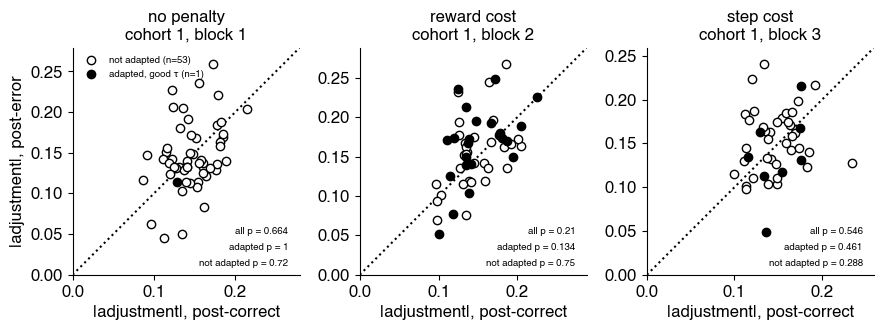

In [11]:
fig_mag, axs_mag = plt.subplots(1, len(BLOCKS), figsize=(3 * len(BLOCKS), 3.3))

for j, block in enumerate(BLOCKS):
    ax = axs_mag[j]
    r = mag_results[block]
    x, y, adapted = r['mag_correct'], r['mag_error'], r['adapted']

    lo = 0.0
    hi = max(x.max(), y.max()) * 1.08
    ax.plot([lo, hi], [lo, hi], 'k:')

    ax.plot(x[~adapted], y[~adapted], 'ko', markerfacecolor=(0.99, 0.99, 0.99),
            label=f'not adapted (n={(~adapted).sum()})')
    ax.plot(x[adapted], y[adapted], 'ko', markerfacecolor='k',
            label=f'adapted, good τ (n={adapted.sum()})')

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_box_aspect(1)
    ax.set_title(f'{CONDITION_LABELS[block]}\ncohort 1, block {block}')
    ax.set_xlabel('|adjustment|, post-correct')
    if j == 0:
        ax.set_ylabel('|adjustment|, post-error')
        ax.legend(loc='upper left', fontsize=7, frameon=False)
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    ax.text(0.95, 0.17, f'all p = {r["p_all"]:.3g}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=7)
    ax.text(0.95, 0.10, f'adapted p = {r["p_adapted"]:.3g}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=7)
    ax.text(0.95, 0.03, f'not adapted p = {r["p_not_adapted"]:.3g}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=7)

plt.tight_layout()
plt.show()